In [1]:
import os
os.environ["OMP_NUM_THREADS"] = os.environ["OPENBLAS_NUM_THREADS"] = "1"   # arriba del todo, antes de importar numpy (reinicia el kernel)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tv_var.harmonic_standardizer import HarmonicStandardizer

from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

from xgboost import XGBRegressor

#### Load Data

In [ ]:
#### PCS
pcs_msl = pd.read_csv('outputs/pca/pcs_msl.csv', index_col=0, parse_dates=True)
pcs_msl_gradient = pd.read_csv('outputs/pca/pcs_msl_gradient.csv', index_col=0, parse_dates=True)
pcs_all = pcs_msl.join(pcs_msl_gradient)
#### Waves
waves_df = pd.read_csv('inputs/waves_bulk.csv', index_col=0, parse_dates=True)
harm_std = HarmonicStandardizer(n_harmonics=3)
harm_std.fit(waves_df.loc['1985-01-01':'2015-12-31'])
waves_df_z = harm_std.transform(waves_df)

In [ ]:
pcs_msl_train = pcs_all.loc['1985-01-01':'2015-12-31']
pcs_msl_predict = pcs_all.loc['2016-01-01':'2025-12-31']
waves_df_train = waves_df_z.loc['1985-01-01':'2015-12-31']
waves_df_predict = waves_df_z.loc['2016-01-01':'2025-12-31']

#### Only MSLP

In [4]:
lags = [0, 6, 12, 18, 24, 30, 36]
pcs_msl_train_lagged = pd.concat({f"l{l}": pcs_msl_train.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(pcs_msl_train.index)
pcs_msl_train_lagged.columns = [f"{c}_l{l[1:]}" for l, c in pcs_msl_train_lagged.columns]
pcs_msl_train_lagged = pcs_msl_train_lagged.dropna()         
print(pcs_msl_train_lagged.shape)  

(271692, 441)


In [5]:
lags = [0, 6, 12, 18, 24, 30, 36]
pcs_msl_predict_lagged = pd.concat({f"l{l}": pcs_msl_predict.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(pcs_msl_predict.index)
pcs_msl_predict_lagged.columns = [f"{c}_l{l[1:]}" for l, c in pcs_msl_predict_lagged.columns]
pcs_msl_predict_lagged = pcs_msl_predict_lagged.dropna()         
print(pcs_msl_predict_lagged.shape)  

waves_df_predict = waves_df_predict.loc[pcs_msl_predict_lagged.index.values]

(87660, 441)


In [6]:
X = pcs_msl_train_lagged.values
Xs = StandardScaler().fit_transform(X)  

y = waves_df_train.loc[pcs_msl_train_lagged.index.values]['VHM0'].values
lasso_cv = LassoCV(cv=5, random_state=0).fit(X=Xs, y=y)

/nfs/home/geocean/alonsoap/.conda/envs/tv_var/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.768145e+01, tolerance: 2.732e+01
  model = cd_fast.enet_coordinate_descent(


In [7]:
# Access the best alpha and coefficients
print("Best Alpha:", lasso_cv.alpha_)
print("Coefficients:", lasso_cv.coef_)
print("R^2 Score:", lasso_cv.score(Xs, y))

Best Alpha: 0.0003390466583519612
Coefficients: [ 6.38904601e-03  1.74931518e-02 -0.00000000e+00  0.00000000e+00
  5.94274902e-03  7.93672353e-02  4.56589973e-02 -1.77347668e-02
  4.94246370e-02  0.00000000e+00  5.55912085e-02 -8.86379913e-02
 -6.41260715e-02  7.17807603e-02  1.02773246e-01  1.14977086e-01
 -3.23946610e-02 -8.28046122e-02 -3.34117525e-02  2.57016964e-03
 -0.00000000e+00 -6.47515686e-02 -3.75288949e-02  1.53549767e-02
 -8.25521129e-02 -0.00000000e+00  0.00000000e+00 -4.79229619e-02
  1.40072573e-02  8.45839376e-04  3.62479279e-02  2.41790367e-02
 -1.12134850e-02  3.43887491e-02 -1.37083354e-02  7.53026928e-03
 -3.41424340e-02 -2.40095145e-02 -2.66670357e-03 -1.14874690e-03
 -1.73703029e-03 -2.07329586e-03  2.11357208e-02  1.16148752e-02
  8.33441706e-03 -5.72004898e-02 -4.36331670e-03  2.03607927e-02
 -1.12095888e-02  2.29825165e-04  3.92068345e-02  8.11134461e-03
 -2.80568763e-04  0.00000000e+00 -5.95825570e-03 -5.73537754e-02
  3.39314194e-02 -3.71999800e-02  3.104557

pc,grad_PC1,grad_PC2,grad_PC3,grad_PC4,grad_PC5,grad_PC6,grad_PC7,grad_PC8,grad_PC9,grad_PC10,...,msl_PC4,msl_PC5,msl_PC6,msl_PC7,msl_PC8,msl_PC9,msl_PC10,msl_PC11,msl_PC12,msl_PC13
lag,,,,,,,,,,,,,,,,,,,,,
0,0.072,0.103,0.115,-0.032,-0.083,-0.033,0.003,-0.000,-0.065,-0.038,...,0.000,0.006,0.079,0.046,-0.018,0.049,0.000,0.056,-0.089,-0.064
6,0.119,0.051,0.093,-0.038,-0.051,-0.028,0.000,-0.001,-0.025,-0.016,...,0.023,-0.000,-0.000,-0.000,-0.065,-0.013,0.023,-0.000,0.040,0.117
12,0.086,0.079,0.080,-0.074,-0.075,-0.017,-0.045,-0.008,-0.056,-0.043,...,0.000,-0.029,-0.015,0.000,-0.000,-0.000,0.000,-0.030,0.000,0.049
18,0.036,0.061,0.041,-0.012,-0.048,-0.024,-0.021,-0.000,-0.045,-0.026,...,0.000,0.000,0.000,0.000,0.000,-0.000,-0.000,-0.000,-0.005,-0.009
24,0.000,0.000,-0.000,-0.000,-0.008,0.000,-0.001,0.019,-0.015,-0.000,...,0.000,0.008,0.012,0.000,0.049,-0.024,0.000,0.000,-0.000,-0.016
30,0.000,-0.000,-0.004,-0.000,-0.039,0.000,0.000,0.000,-0.010,-0.000,...,0.000,0.003,0.038,-0.000,0.024,-0.004,0.028,0.043,0.000,0.000
36,-0.000,0.024,0.004,-0.000,-0.039,-0.005,0.003,0.032,0.016,-0.015,...,0.049,0.000,0.060,-0.024,-0.028,-0.026,0.000,0.034,-0.025,0.004


suma |coef| por PC:
 pc
msl_PC2      0.452
grad_PC5     0.342
grad_PC3     0.336
grad_PC2     0.317
grad_PC1     0.312
msl_PC13     0.260
msl_PC3      0.249
grad_PC9     0.233
grad_PC12    0.229
msl_PC1      0.220
grad_PC11    0.214
msl_PC6      0.204
grad_PC16    0.187
grad_PC33    0.186
msl_PC8      0.183
grad_PC35    0.174
msl_PC11     0.163
msl_PC12     0.159
grad_PC15    0.157
grad_PC4     0.156
grad_PC23    0.144
grad_PC10    0.137
grad_PC44    0.127
grad_PC20    0.119
grad_PC22    0.119
msl_PC9      0.116
grad_PC14    0.109
grad_PC6     0.107
grad_PC43    0.103
grad_PC18    0.098
grad_PC29    0.094
grad_PC30    0.092
grad_PC45    0.086
grad_PC21    0.086
grad_PC48    0.081
msl_PC4      0.072
grad_PC7     0.072
grad_PC38    0.071
msl_PC7      0.069
grad_PC46    0.069
grad_PC17    0.067
grad_PC19    0.062
grad_PC26    0.061
grad_PC50    0.061
grad_PC25    0.060
grad_PC8     0.059
grad_PC32    0.059
grad_PC24    0.057
msl_PC10     0.051
grad_PC36    0.050
grad_PC13    0.049
msl_PC5

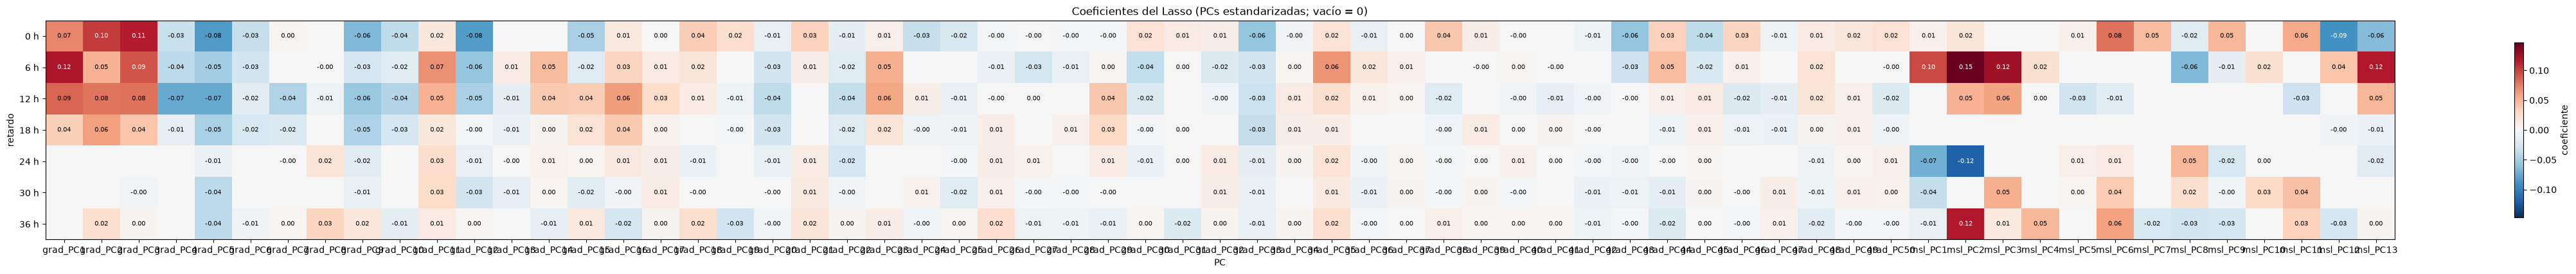

In [9]:
cols = pcs_msl_train_lagged.columns                            # p. ej. "msl_PC4_l12"
coef = pd.Series(lasso_cv.coef_, index=cols)                      # tu modelo Lasso ajustado
M = pd.DataFrame({"pc": [c.rsplit("_l", 1)[0] for c in cols],      # "msl_PC4" / "grad_PC4" (prefijo incluido: PC4 existe en ambas familias)
                  "lag": [int(c.rsplit("_l", 1)[1]) for c in cols],
                  "coef": coef.values})
M = M.pivot(index="lag", columns="pc", values="coef")

def _pc_key(s):
    fam, num = s.rsplit("_PC", 1)
    return (fam, int(num))

M = M[sorted(M.columns, key=_pc_key)].sort_index()

lim = np.abs(M.values).max()
fig, ax = plt.subplots(figsize=(1.0 + 0.62 * M.shape[1], 1.0 + 0.45 * M.shape[0]), constrained_layout=True)
im = ax.imshow(M.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.iloc[i, j]
        if v != 0:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 0.6 * lim else "black")
ax.set_xticks(range(M.shape[1]), M.columns)
ax.set_yticks(range(M.shape[0]), [f"{l} h" for l in M.index])
ax.set(xlabel="PC", ylabel="retardo", title="Coeficientes del Lasso (PCs estandarizadas; vacío = 0)")
fig.colorbar(im, ax=ax, shrink=0.8, label="coeficiente")
display(M.round(3))
print("suma |coef| por PC:\n", M.abs().sum().sort_values(ascending=False).round(3).to_string())


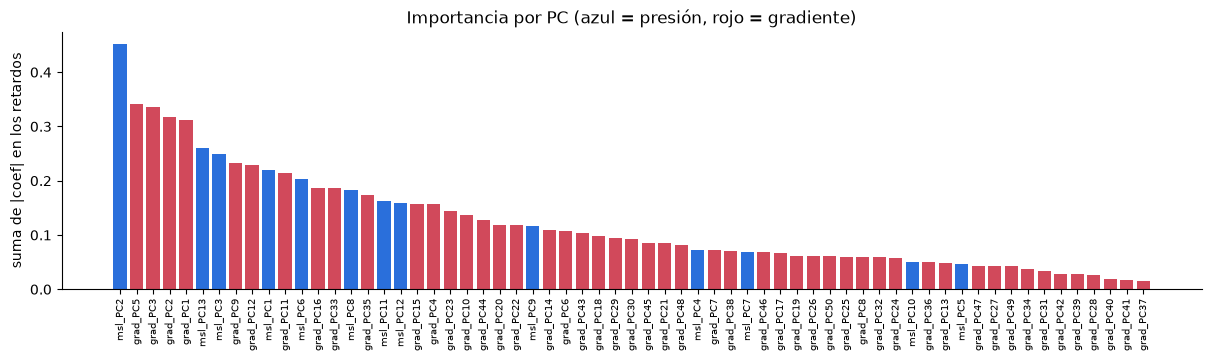

In [10]:
imp = M.abs().sum().sort_values(ascending=False)                      # suma de |coef| por PC
fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.bar(range(len(imp)), imp.values,
       color=["#2a6fdb" if n.startswith("msl") else "#d1495b" for n in imp.index])
ax.set_xticks(range(len(imp)), imp.index, rotation=90, fontsize=7)
ax.set(ylabel="suma de |coef| en los retardos", title="Importancia por PC (azul = presión, rojo = gradiente)")
ax.spines[["top", "right"]].set_visible(False)

In [11]:
xgboost_model = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6,
                       min_child_weight=200, subsample=0.8, colsample_bytree=0.8,
                       tree_method="hist", n_jobs=-1, random_state=0
)


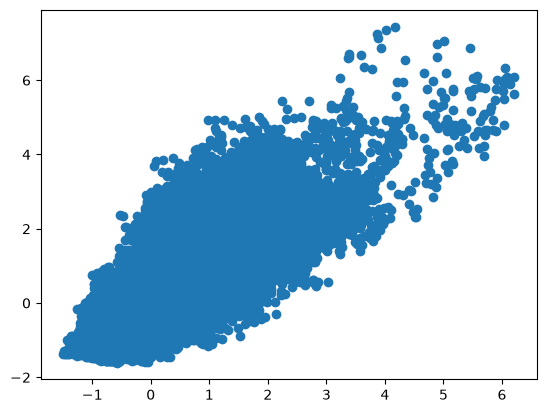

In [12]:
xgboost_model.fit(pcs_msl_train_lagged.values, y)
y_model = xgboost_model.predict(pcs_msl_predict_lagged.values)
plt.scatter(y_model,waves_df_predict['VHM0'].values)

In [13]:
from sklearn.metrics import r2_score

obs = waves_df_predict['VHM0'].values        # Z observado, mismas horas que la predicción
print(f"R² horario (prueba):  {r2_score(obs, y_model):.3f}")

# en escala diaria, la de tu objetivo de cronología
d = pd.DataFrame({"obs": obs, "pred": y_model}, index=waves_df_predict.index.values).resample("D").mean().dropna()
print(f"R² diario (prueba):   {r2_score(d.obs, d.pred):.3f}")
print(f"correlación diaria:   {d.obs.corr(d.pred):.3f}")

R² horario (prueba):  0.665
R² diario (prueba):   0.743
correlación diaria:   0.863


 1 PCs (+msl_PC2): R² = 0.078   (1 s)
 2 PCs (+grad_PC5): R² = 0.209   (1 s)
 3 PCs (+grad_PC3): R² = 0.313   (2 s)
 4 PCs (+grad_PC2): R² = 0.360   (3 s)
 5 PCs (+grad_PC1): R² = 0.380   (3 s)
 6 PCs (+msl_PC13): R² = 0.396   (4 s)
 7 PCs (+msl_PC3): R² = 0.409   (4 s)
 8 PCs (+grad_PC9): R² = 0.445   (5 s)
 9 PCs (+grad_PC12): R² = 0.486   (6 s)
10 PCs (+msl_PC1): R² = 0.489   (7 s)
11 PCs (+grad_PC11): R² = 0.503   (7 s)
12 PCs (+msl_PC6): R² = 0.511   (8 s)
13 PCs (+grad_PC16): R² = 0.530   (9 s)
14 PCs (+grad_PC33): R² = 0.546   (10 s)
15 PCs (+msl_PC8): R² = 0.547   (10 s)
18 PCs (+msl_PC12): R² = 0.570   (13 s)
21 PCs (+grad_PC23): R² = 0.588   (15 s)
24 PCs (+grad_PC20): R² = 0.602   (18 s)
27 PCs (+grad_PC14): R² = 0.606   (21 s)
30 PCs (+grad_PC18): R² = 0.615   (24 s)
33 PCs (+grad_PC45): R² = 0.618   (27 s)
36 PCs (+msl_PC4): R² = 0.631   (30 s)
39 PCs (+msl_PC7): R² = 0.634   (33 s)
42 PCs (+grad_PC19): R² = 0.635   (36 s)
45 PCs (+grad_PC25): R² = 0.636   (39 s)
48 PCs (+

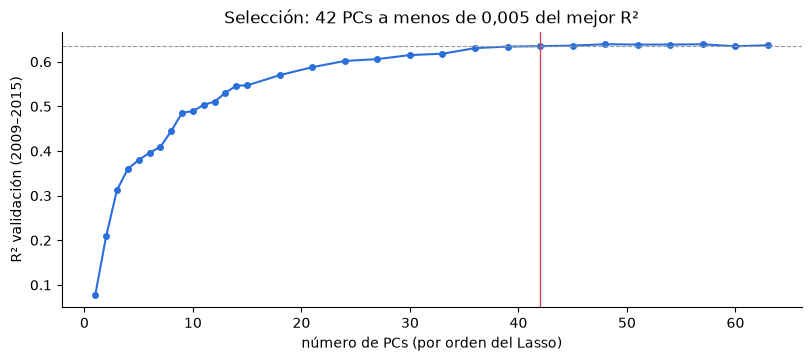

In [14]:
import time
from sklearn.metrics import r2_score

orden = imp.index.tolist()                                # PCs ordenadas por el Lasso
Xall, yall = pcs_msl_train_lagged, pd.Series(y, index=pcs_msl_train_lagged.index)
tr = Xall.index < "2009-01-01"                            # ajuste interno
va = ~tr                                                  # validación interna (2009–2015)
paso = 3                                                  # una hora de cada 3 para ir más rápido (son casi iguales)

def r2_con(pcs):
    cols = [c for c in Xall.columns if c.rsplit("_l", 1)[0] in pcs]
    m = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, min_child_weight=200,
                     subsample=0.8, colsample_bytree=0.8, tree_method="hist", n_jobs=32, random_state=0)
    m.fit(Xall.loc[tr, cols].iloc[::paso], yall[tr].iloc[::paso])
    return r2_score(yall[va], m.predict(Xall.loc[va, cols]))

ks = list(range(1, 16)) + list(range(18, len(orden) + 1, 3))
if ks[-1] != len(orden):
    ks.append(len(orden))
curva = {}
for k in ks:
    t = time.time()
    curva[k] = r2_con(orden[:k])
    print(f"{k:>2} PCs (+{orden[k-1]}): R² = {curva[k]:.3f}   ({time.time() - t:.0f} s)")

curva = pd.Series(curva)
k_min = int(curva.index[curva >= curva.max() - 0.005][0])     # menos PCs a ≤ 0,005 del máximo
fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.plot(curva.index, curva.values, "o-", color="#2a6fdb", ms=4)
ax.axhline(curva.max() - 0.005, color="0.6", lw=0.8, ls="--")
ax.axvline(k_min, color="#d1495b", lw=1)
ax.set(xlabel="número de PCs (por orden del Lasso)", ylabel="R² validación (2009–2015)",
       title=f"Selección: {k_min} PCs a menos de 0,005 del mejor R²")
ax.spines[["top", "right"]].set_visible(False)
seleccion = orden[:k_min]
print(seleccion)

In [16]:
pcs_g_rec = pd.read_csv("/nfs/home/geocean/alonsoap/pcs_grad_reconstruido_13msl.csv", index_col=0, parse_dates=True)

In [19]:
print(pcs_msl_gradient.columns[:3].tolist(), pcs_g_rec.columns[:3].tolist())
print(pcs_g_rec.index[0], pcs_g_rec.index[-1], pcs_g_rec.shape)

['grad_PC1', 'grad_PC2', 'grad_PC3'] ['grad_PC1', 'grad_PC2', 'grad_PC3']
2016-01-01 00:00:00 2025-12-31 23:00:00 (87672, 50)


In [20]:
pcs_test_rec = pcs_msl.loc["2016":"2025"].join(pcs_g_rec)   # 13 presión + 50 gradiente reconstruido

X_test_rec = pd.concat({f"l{l}": pcs_test_rec.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(pcs_test_rec.index)
X_test_rec.columns = [f"{c}_l{l[1:]}" for l, c in X_test_rec.columns]
X_test_rec = X_test_rec.dropna()
print(X_test_rec.shape)

(87636, 441)


In [23]:
y_test = waves_df_predict['VHM0']                       # Z observado en test (ya alineado con pcs_msl_predict_lagged)

def r2_y_corr(X):
    X = X[pcs_msl_predict_lagged.columns]               # mismo orden de columnas que en el entrenamiento
    y = y_test.reindex(X.index).dropna()
    p = pd.Series(xgboost_model.predict(X.loc[y.index].values), index=y.index)
    yd, pd_ = y.resample("D").mean(), p.resample("D").mean()
    return r2_score(y, p), yd.corr(pd_)

print("gradiente real        : R² %.3f | corr diaria %.3f" % r2_y_corr(pcs_msl_predict_lagged))
print("gradiente reconstruido: R² %.3f | corr diaria %.3f" % r2_y_corr(X_test_rec))

gradiente real        : R² 0.665 | corr diaria 0.863
gradiente reconstruido: R² 0.171 | corr diaria 0.680
